# Лабораторная работа 2.1

In [65]:
import pandas as pd
from sklearn import linear_model as lm
import matplotlib.pyplot as plt
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, r2_score, mean_absolute_percentage_error

In [68]:
FILEPATH = 'data/lab2_1_DS.csv'
df = pd.read_csv(FILEPATH)

X = df.iloc[:, 0:2] 
y = df.iloc[:, -1]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

simple_reg = lm.LinearRegression()
ridge_reg = lm.Ridge()
lasso_reg = lm.Lasso()
elastic_reg = lm.ElasticNet()

simple_reg.fit(X_train, y_train)
ridge_reg.fit(X_train, y_train)
lasso_reg.fit(X_train, y_train)
elastic_reg.fit(X_train, y_train)

print(simple_reg.intercept_, simple_reg.coef_)
print(ridge_reg.intercept_, ridge_reg.coef_)
print(lasso_reg.intercept_, lasso_reg.coef_)
print(elastic_reg.intercept_, elastic_reg.coef_)


31465.056418503933 [-101.0592335  2154.80549277]
31442.30728744568 [ -98.64426618 2143.62229033]
31464.317325810363 [-101.02485242 2154.7050736 ]
31292.74266845885 [ -82.50460658 2068.53293928]


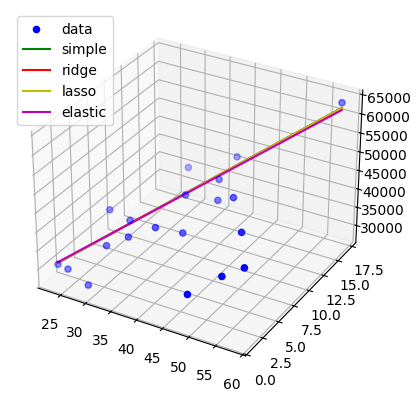

In [69]:
fig, ax = plt.subplots(subplot_kw={'projection': '3d'})
#ax.view_init(elev=45, azim=0, roll=0)

x1 = np.linspace(min(df['age']), max(df['age']), 100)
x2 = np.linspace(min(df['experience']), max(df['experience']), 100)

data = ax.scatter(df['age'], df['experience'], df['income'], label='data', marker='o', color='b')

simple = ax.plot(x1, x2, simple_reg.intercept_ + simple_reg.coef_[0] * x1 + simple_reg.coef_[1] * x2, label='simple', color='g')
ridge =ax.plot(x1, x2, ridge_reg.intercept_ + ridge_reg.coef_[0] * x1 + ridge_reg.coef_[1] * x2, label='ridge', color='r')
lasso = ax.plot(x1, x2, lasso_reg.intercept_ + lasso_reg.coef_[0] * x1 + lasso_reg.coef_[1] * x2, label='lasso', color='y')
elastic = ax.plot(x1, x2, elastic_reg.intercept_ + elastic_reg.coef_[0] * x1 + elastic_reg.coef_[1] * x2, label='elastic', color='m')

ax.legend()

In [ ]:
print('Simple regression')
print(f'MAE: {mean_absolute_error(y_test, simple_reg.predict(X_test))}')
print(f'MAPE: {mean_absolute_percentage_error(y_test, simple_reg.predict(X_test))}')
print("R2: %.2f" % r2_score(y_test, simple_reg.predict(X_test)))

print()

print('Ridge regression')
print(f'MAE: {mean_absolute_error(y_test, ridge_reg.predict(X_test))}')
print(f'MAPE: {mean_absolute_percentage_error(y_test, ridge_reg.predict(X_test))}')
print(f"R2: {r2_score(y_test, ridge_reg.predict(X_test)})")

print()

print('LASSO regression')
print(f'MAE: {mean_absolute_error(y_test, lasso_reg.predict(X_test))}')
print(f'MAPE: {mean_absolute_percentage_error(y_test, lasso_reg.predict(X_test))}')
print(f"R2: {r2_score(y_test, lasso_reg.predict(X_test))}")



Simple regression
MAE: 797.9113810821873
MAPE: 0.022820067951610557
R2: 0.94

Ridge regression
MAE: 808.1785804530791
MAPE: 0.023157894639344676
R2: 0.94

LASSO regression
MAE: 797.9234317367345
MAPE: 0.022820337130444582
R2: 0.94
